# Halo Exchange and Communication Overlap

**Learning goal:** Implement correct periodic halo exchange for a decomposed 2D stencil, separate interior and boundary work, and quantify modeled strong-scaling limits with and without communication overlap.

**Time:** 60-90 minutes. Dependencies: NumPy, Matplotlib, and Plotly. Synthetic, dimensionless data. The core runs in one Python kernel using emulated ranks; no MPI installation is required. Emulation timings are not parallel performance measurements. Optional MPI work is separate.

The reusable skill is ownership and scheduling: what data each rank owns, what it must receive, and which work can run before those receives complete. The physical grid stays fixed.

## 1. Governing model and reference solution

Use one explicit step of periodic 2D diffusion on the unit square:
$$u_t=\kappa(u_{xx}+u_{yy}),\quad
u^{n+1}_{i,j}=u^n_{i,j}+\mu\left(u^n_{i-1,j}+u^n_{i+1,j}+u^n_{i,j-1}+u^n_{i,j+1}-4u^n_{i,j}\right),$$
with diffusivity $\kappa=0.01\ \mathrm{m^2/s}$ (dimensionless unit square), grid spacing $\Delta x=1/N\ \mathrm{m}$, time step $\Delta t=\mu\Delta x^2/\kappa\ \mathrm{s}$, and dimensionless diffusion number $\mu=0.2$. Set $N=256$ in both directions and advance $\mathrm{STEPS}=20$ steps. Cell centers are $x_i=(i+\tfrac12)\Delta x$, $y_j=(j+\tfrac12)\Delta x$. Initial state:
$$u(x,y)=1+0.2\sin(2\pi x)\cos(4\pi y)\quad[\text{dimensionless}].$$

The serial reference uses `np.roll` for periodic wraparound in both directions. It establishes the ground truth that the decomposed, halo-exchanged implementation (Section 2) must reproduce exactly: the decomposition changes only how work is scheduled and where data lives, not the numerical operator. This is an exactness check on a parallel algorithm, not a discretization-accuracy study (that is Section 3's distinction).

Reference: periodic finite-difference stencils and `numpy.roll` semantics, NumPy documentation, https://numpy.org/doc/stable/reference/generated/numpy.roll.html .

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from pathlib import Path
from IPython.display import Markdown, display

N = 256
MU = 0.2
STEPS = 20
KAPPA = 0.01
DX = 1.0 / N
DT = MU * DX**2 / KAPPA
BYTES_PER_FLOAT = 8

x = (np.arange(N) + 0.5) * DX
X, Y = np.meshgrid(x, x, indexing="ij")
u0 = 1.0 + 0.2 * np.sin(2 * np.pi * X) * np.cos(4 * np.pi * Y)


def serial_step(u, mu=MU):
    """One periodic 5-point diffusion update via np.roll."""
    return u + mu * (
        np.roll(u, 1, axis=0) + np.roll(u, -1, axis=0)
        + np.roll(u, 1, axis=1) + np.roll(u, -1, axis=1)
        - 4 * u
    )


serial_history = [u0.copy()]
u_serial = u0.copy()
for _ in range(STEPS):
    u_serial = serial_step(u_serial)
    serial_history.append(u_serial.copy())

print(f"dx={DX:.6f} m, dt={DT:.6e} s, mu={MU}, initial mean={u0.mean():.6f}")
print(f"serial reference: step 1 max={serial_history[1].max():.6f}, "
      f"step {STEPS} max={serial_history[STEPS].max():.6f}")

dx=0.003906 m, dt=3.051758e-04 s, mu=0.2, initial mean=1.000000
serial reference: step 1 max=1.199804, step 20 max=1.197530


## 2. Discretization and conditions

### Cartesian ownership and halo buffers

Use $P \in \{1,4,16,64\}$ ranks arranged on square processor grids $(1,1)$, $(2,2)$, $(4,4)$, $(8,8)$. Rank $(r,c)$ owns a contiguous $n \times n$ block, $n=N/\sqrt{P}$, stored with one ghost layer around the owned interior (padded shape $(n+2)\times(n+2)$).

`split_global` carves the global array into owned blocks with zeroed ghosts. `gather_global` is its exact inverse on the owned interiors. `exchange_halos` snapshots the four owned faces required by the five-point stencil (corners are unused) from every block *before* writing any ghost cell, then installs each block's four ghost rows/columns from the matching neighbor's snapshot. Periodic neighbors wrap in both processor-grid directions via `% d`, which also covers $P=1$ (a rank is its own neighbor in all four directions) and the $P=4$ case where two directions can share the same physical neighbor.

Correctness is verified against **global index IDs** (`np.arange(N*N)`), not a smooth wave, so a halo swapped between the wrong pair of neighbors cannot hide behind symmetric data: every received ghost value must equal the corresponding periodic global index exactly (Section 6).

In [2]:
def split_global(u, dims):
    """Split a global (N, N) array into {(r, c): padded (n+2, n+2) block} with one ghost layer."""
    d, _ = dims
    n = u.shape[0] // d
    blocks = {}
    for r in range(d):
        for c in range(d):
            blk = np.zeros((n + 2, n + 2), dtype=u.dtype)
            blk[1:-1, 1:-1] = u[r * n:(r + 1) * n, c * n:(c + 1) * n]
            blocks[(r, c)] = blk
    return blocks


def gather_global(blocks, dims):
    """Inverse of split_global: reassemble owned interiors into one (N, N) array."""
    d, _ = dims
    n = next(iter(blocks.values())).shape[0] - 2
    out = np.empty((n * d, n * d), dtype=next(iter(blocks.values())).dtype)
    for (r, c), blk in blocks.items():
        out[r * n:(r + 1) * n, c * n:(c + 1) * n] = blk[1:-1, 1:-1]
    return out


def _snapshot_faces(blocks):
    """Snapshot the four owned send-faces of every block before any ghost is written."""
    faces = {}
    for key, blk in blocks.items():
        faces[key] = {
            "N": blk[1, 1:-1].copy(),
            "S": blk[-2, 1:-1].copy(),
            "W": blk[1:-1, 1].copy(),
            "E": blk[1:-1, -2].copy(),
        }
    return faces


def exchange_halos(blocks, dims):
    """Snapshot all send faces, then install every received ghost from those snapshots (in place)."""
    d, _ = dims
    faces = _snapshot_faces(blocks)
    for (r, c), blk in blocks.items():
        blk[0, 1:-1] = faces[((r - 1) % d, c)]["S"]
        blk[-1, 1:-1] = faces[((r + 1) % d, c)]["N"]
        blk[1:-1, 0] = faces[(r, (c - 1) % d)]["E"]
        blk[1:-1, -1] = faces[(r, (c + 1) % d)]["W"]
    return blocks


def halo_matches_global_id(dims):
    """Check every received ghost face against the corresponding periodic global index."""
    d, _ = dims
    N_local = 256
    ids = np.arange(N_local * N_local, dtype=float).reshape(N_local, N_local)
    blocks = split_global(ids, dims)
    exchange_halos(blocks, dims)
    n = N_local // d
    for (r, c), blk in blocks.items():
        cols = np.arange(c * n, c * n + n) % N_local
        rows = np.arange(r * n, r * n + n) % N_local
        if not np.array_equal(blk[0, 1:-1], ids[(r * n - 1) % N_local, cols]):
            return False
        if not np.array_equal(blk[-1, 1:-1], ids[(r * n + n) % N_local, cols]):
            return False
        if not np.array_equal(blk[1:-1, 0], ids[rows, (c * n - 1) % N_local]):
            return False
        if not np.array_equal(blk[1:-1, -1], ids[rows, (c * n + n) % N_local]):
            return False
    return True


DECOMPOSITIONS = [(1, (1, 1)), (4, (2, 2)), (16, (4, 4)), (64, (8, 8))]
for P, dims in DECOMPOSITIONS:
    print(f"P={P:<3d} dims={dims} halo-matches-global-id: {halo_matches_global_id(dims)}")

P=1   dims=(1, 1) halo-matches-global-id: True
P=4   dims=(2, 2) halo-matches-global-id: True
P=16  dims=(4, 4) halo-matches-global-id: True
P=64  dims=(8, 8) halo-matches-global-id: True


### Scheduling interior and boundary work

Two schedules, each writing every owned cell exactly once per step using **distinct old/new buffers** (no in-place aliasing):

1. **Blocking:** exchange all old-state faces first, then update every owned cell from the now-complete padded block.
2. **Overlap emulation:** snapshot send faces; compute the strict interior ($(n-2)^2$ cells) from old data alone (it needs no ghost values); install the received faces; compute the remaining boundary ring ($n^2-(n-2)^2$ cells); swap buffers.

This ordering emulates a *legal* MPI overlap schedule (interior work that does not depend on the halo runs before the receives are required) but does not implement concurrent communication in this single Python kernel — see Section 7 for why nonblocking calls alone do not establish that.

In [3]:
def _update_full(blk, mu=MU):
    """Five-point stencil update for every owned cell of a padded block (ghosts must be current)."""
    return blk[1:-1, 1:-1] + mu * (
        blk[0:-2, 1:-1] + blk[2:, 1:-1] + blk[1:-1, 0:-2] + blk[1:-1, 2:] - 4 * blk[1:-1, 1:-1]
    )


def decomposed_step(blocks, dims, schedule, mu=MU, track_writes=False):
    """Advance one step with 'blocking' or 'overlap' scheduling using distinct old/new buffers."""
    d, _ = dims
    n = next(iter(blocks.values())).shape[0] - 2
    write_count = {key: np.zeros((n, n), dtype=int) for key in blocks} if track_writes else None

    if schedule == "blocking":
        exchange_halos(blocks, dims)
        new_blocks = {}
        for key, blk in blocks.items():
            nb = np.zeros_like(blk)
            nb[1:-1, 1:-1] = _update_full(blk, mu)
            new_blocks[key] = nb
            if track_writes:
                write_count[key] += 1
        return new_blocks, write_count

    if schedule == "overlap":
        faces = _snapshot_faces(blocks)
        new_blocks = {key: np.zeros_like(blk) for key, blk in blocks.items()}
        ring_mask = np.ones((n, n), dtype=bool)
        if n > 2:
            ring_mask[1:-1, 1:-1] = False

        for key, blk in blocks.items():
            interior = blk[1:-1, 1:-1]
            if n > 2:
                core = interior[1:-1, 1:-1] + mu * (
                    interior[0:-2, 1:-1] + interior[2:, 1:-1]
                    + interior[1:-1, 0:-2] + interior[1:-1, 2:] - 4 * interior[1:-1, 1:-1]
                )
                new_blocks[key][2:-2, 2:-2] = core
                if track_writes:
                    write_count[key][1:-1, 1:-1] += 1

        for (r, c), blk in blocks.items():
            blk[0, 1:-1] = faces[((r - 1) % d, c)]["S"]
            blk[-1, 1:-1] = faces[((r + 1) % d, c)]["N"]
            blk[1:-1, 0] = faces[(r, (c - 1) % d)]["E"]
            blk[1:-1, -1] = faces[(r, (c + 1) % d)]["W"]

        for key, blk in blocks.items():
            full_new = _update_full(blk, mu)
            new_blocks[key][1:-1, 1:-1][ring_mask] = full_new[ring_mask]
            if track_writes:
                write_count[key][ring_mask] += 1

        return new_blocks, write_count

    raise ValueError(f"unknown schedule {schedule!r}")


SCHEDULES = ("blocking", "overlap")
print("decomposed_step defined for schedules:", SCHEDULES)

decomposed_step defined for schedules: ('blocking', 'overlap')


## 3. Error measures and expected behavior

The error measure is the maximum absolute difference between a gathered decomposed field and the serial reference at the same step,
$$e(P,\text{schedule},\text{step})=\max_{i,j}\left|u^{\text{decomposed}}_{i,j}-u^{\text{serial}}_{i,j}\right|,$$
evaluated after step 1 and step 20 for every $P\in\{1,4,16,64\}$ and both schedules.

**Expected behavior:** because the decomposition and halo exchange reproduce the identical periodic five-point stencil with no approximation, $e$ should sit at floating-point round-off ($\lesssim 10^{-12}$, the accumulated error of ~$10^2$–$10^4$ floating-point operations per cell over 20 steps) for every $P$ and schedule — it should **not** shrink with finer decomposition or grow with step count beyond that round-off floor. A larger $e$ would indicate a genuine decomposition bug (e.g., a swapped neighbor or a double-written cell), not a discretization-accuracy issue; there is no mesh or time-step refinement in this notebook (see Section 6 note).

In [4]:
comparisons = {}
for P, dims in DECOMPOSITIONS:
    for schedule in SCHEDULES:
        blocks = split_global(u0, dims)
        for step in range(1, STEPS + 1):
            blocks, _ = decomposed_step(blocks, dims, schedule)
            if step in (1, STEPS):
                gathered = gather_global(blocks, dims)
                err = float(np.max(np.abs(gathered - serial_history[step])))
                comparisons[(P, schedule, step)] = err

for (P, schedule, step), err in comparisons.items():
    print(f"P={P:<3d} {schedule:<9s} step={step:<2d} max|diff|={err:.3e}")

assert all(err < 1e-12 for err in comparisons.values()), "decomposition error exceeds round-off floor"
print("\nAll decomposition errors are at the round-off floor (<1e-12), as expected.")

P=1   blocking  step=1  max|diff|=0.000e+00
P=1   blocking  step=20 max|diff|=0.000e+00
P=1   overlap   step=1  max|diff|=0.000e+00
P=1   overlap   step=20 max|diff|=0.000e+00
P=4   blocking  step=1  max|diff|=0.000e+00
P=4   blocking  step=20 max|diff|=0.000e+00
P=4   overlap   step=1  max|diff|=0.000e+00
P=4   overlap   step=20 max|diff|=0.000e+00
P=16  blocking  step=1  max|diff|=0.000e+00
P=16  blocking  step=20 max|diff|=0.000e+00
P=16  overlap   step=1  max|diff|=0.000e+00
P=16  overlap   step=20 max|diff|=0.000e+00
P=64  blocking  step=1  max|diff|=0.000e+00
P=64  blocking  step=20 max|diff|=0.000e+00
P=64  overlap   step=1  max|diff|=0.000e+00
P=64  overlap   step=20 max|diff|=0.000e+00

All decomposition errors are at the round-off floor (<1e-12), as expected.


## 4. Results and convergence

### Decomposition exactness across $P$

Section 3 already shows: for every $P$ and both schedules, the decomposed solution matches the serial reference to round-off after both 1 and 20 steps. This is the "convergence" result for the parallel algorithm itself — exactness independent of $P$, not an order-of-accuracy trend.

### Communication and scaling model

Hypothetical hardware parameters: per-message latency $\alpha=2\ \mu\mathrm{s}$, payload bandwidth $B=10\ \mathrm{GB/s}$, stencil cost $c=2\ \mathrm{ns}$ per owned cell, float64 payload $b=8\ \mathrm{bytes}$. Four face messages are assumed serialized through one rank's communication path:
$$T_{comm}=4\alpha+\frac{4nb}{B},\qquad T_{int}=c(n-2)^2,\qquad T_{ring}=c\left[n^2-(n-2)^2\right].$$
For $P>1$:
$$T_{block}=T_{int}+T_{ring}+T_{comm},\qquad T_{overlap}=T_{ring}+\max(T_{int},T_{comm}).$$
For $P=1$, bypass messaging: $T_1=cN^2$ for both schedules (serial reference time at fixed global size). Speedup $S(P)=T_1/T(P)$, efficiency $E=S/P$, hidden fraction $\min(T_{int},T_{comm})/T_{comm}$. **These are idealized lower-bound models**: perfect independent progress, no packing, synchronization, contention, or load imbalance — not a performance prediction for real hardware.

In [5]:
def scaling_model(P, alpha=2e-6, bandwidth=10e9, cost=2e-9, N=N, b=BYTES_PER_FLOAT):
    """Idealized rank-local costs, ideal overlap, speedup, and efficiency at fixed global size N."""
    T1 = cost * N**2
    if P == 1:
        return dict(P=P, n=float(N), T_int=T1, T_ring=0.0, T_comm=0.0,
                    T_block=T1, T_overlap=T1, S_block=1.0, S_overlap=1.0,
                    E_block=1.0, E_overlap=1.0, hidden_fraction=0.0)
    n = N / np.sqrt(P)
    T_comm = 4 * alpha + 4 * n * b / bandwidth
    T_int = cost * (n - 2) ** 2
    T_ring = cost * (n ** 2 - (n - 2) ** 2)
    T_block = T_int + T_ring + T_comm
    T_overlap = T_ring + max(T_int, T_comm)
    S_block = T1 / T_block
    S_overlap = T1 / T_overlap
    return dict(P=P, n=n, T_int=T_int, T_ring=T_ring, T_comm=T_comm,
                T_block=T_block, T_overlap=T_overlap, S_block=S_block, S_overlap=S_overlap,
                E_block=S_block / P, E_overlap=S_overlap / P,
                hidden_fraction=min(T_int, T_comm) / T_comm)


P_GRID = [1, 4, 16, 64, 256, 1024, 4096]
default_rows = [scaling_model(P) for P in P_GRID]

header = "| P | n | T_int (s) | T_ring (s) | T_comm (s) | T_block (s) | T_overlap (s) | S_block | S_overlap | E_block | E_overlap |"
sep = "|---|---|---|---|---|---|---|---|---|---|---|"
rows = [header, sep]
for r in default_rows:
    rows.append(
        f"| {r['P']} | {r['n']:.1f} | {r['T_int']:.3e} | {r['T_ring']:.3e} | {r['T_comm']:.3e} | "
        f"{r['T_block']:.3e} | {r['T_overlap']:.3e} | {r['S_block']:.2f} | {r['S_overlap']:.2f} | "
        f"{r['E_block']:.3f} | {r['E_overlap']:.3f} |"
    )
display(Markdown("\n".join(rows)))

crossover_P = next((r["P"] for r in default_rows if r["P"] > 1 and r["T_int"] < r["T_comm"]), None)
below_half_block = next((r["P"] for r in default_rows if r["E_block"] < 0.5), None)
below_half_overlap = next((r["P"] for r in default_rows if r["E_overlap"] < 0.5), None)
print(f"\nFirst P with T_int < T_comm: {crossover_P if crossover_P is not None else 'no crossing in P_GRID'}")
print(f"First P with E_block < 0.5: {below_half_block if below_half_block is not None else 'no crossing in P_GRID'}")
print(f"First P with E_overlap < 0.5: {below_half_overlap if below_half_overlap is not None else 'no crossing in P_GRID'}")

| P | n | T_int (s) | T_ring (s) | T_comm (s) | T_block (s) | T_overlap (s) | S_block | S_overlap | E_block | E_overlap |
|---|---|---|---|---|---|---|---|---|---|---|
| 1 | 256.0 | 1.311e-04 | 0.000e+00 | 0.000e+00 | 1.311e-04 | 1.311e-04 | 1.00 | 1.00 | 1.000 | 1.000 |
| 4 | 128.0 | 3.175e-05 | 1.016e-06 | 8.410e-06 | 4.118e-05 | 3.277e-05 | 3.18 | 4.00 | 0.796 | 1.000 |
| 16 | 64.0 | 7.688e-06 | 5.040e-07 | 8.205e-06 | 1.640e-05 | 8.709e-06 | 7.99 | 15.05 | 0.500 | 0.941 |
| 64 | 32.0 | 1.800e-06 | 2.480e-07 | 8.102e-06 | 1.015e-05 | 8.350e-06 | 12.91 | 15.70 | 0.202 | 0.245 |
| 256 | 16.0 | 3.920e-07 | 1.200e-07 | 8.051e-06 | 8.563e-06 | 8.171e-06 | 15.31 | 16.04 | 0.060 | 0.063 |
| 1024 | 8.0 | 7.200e-08 | 5.600e-08 | 8.026e-06 | 8.154e-06 | 8.082e-06 | 16.08 | 16.22 | 0.016 | 0.016 |
| 4096 | 4.0 | 8.000e-09 | 2.400e-08 | 8.013e-06 | 8.045e-06 | 8.037e-06 | 16.29 | 16.31 | 0.004 | 0.004 |


First P with T_int < T_comm: 16
First P with E_block < 0.5: 16
First P with E_overlap < 0.5: 64


### Latency/bandwidth sensitivity of the 50% efficiency threshold

Sweep $\alpha\in\{0.2,2,20\}\ \mu\mathrm{s}$ and $B\in\{1,10,100\}\ \mathrm{GB/s}$ at fixed global $N=256$; report the first $P\in P_{\text{grid}}$ at which $E_{overlap}<0.5$ for each combination (interactive exploration of the full curve is in Section 5).

In [6]:
ALPHAS = (0.2e-6, 2e-6, 20e-6)
BANDWIDTHS = (1e9, 10e9, 100e9)

sens_header = "| alpha (us) \\ B (GB/s) | " + " | ".join(f"{bw/1e9:.0f}" for bw in BANDWIDTHS) + " |"
sens_sep = "|---|" + "---|" * len(BANDWIDTHS)
sens_rows = [sens_header, sens_sep]
sensitivity = {}
for alpha in ALPHAS:
    cells_row = []
    for bandwidth in BANDWIDTHS:
        rows = [scaling_model(P, alpha=alpha, bandwidth=bandwidth) for P in P_GRID]
        first_below = next((r["P"] for r in rows if r["E_overlap"] < 0.5), None)
        sensitivity[(alpha, bandwidth)] = rows
        cells_row.append(str(first_below) if first_below is not None else "none in grid")
    sens_rows.append(f"| {alpha*1e6:.1f} | " + " | ".join(cells_row) + " |")
display(Markdown("\n".join(sens_rows)))

| alpha (us) \ B (GB/s) | 1 | 10 | 100 |
|---|---|---|---|
| 0.2 | 256 | 1024 | 1024 |
| 2.0 | 64 | 64 | 64 |
| 20.0 | 4 | 4 | 4 |

## 5. Solution and diagnostic plots

Static Matplotlib figures for the fixed-parameter results (initial/final fields, decomposition-error history, modeled speedup and efficiency, and the interior/ring/communication cost breakdown), and one interactive Plotly explorer for the two-parameter ($\alpha$, $B$) sensitivity sweep per Rule 3.

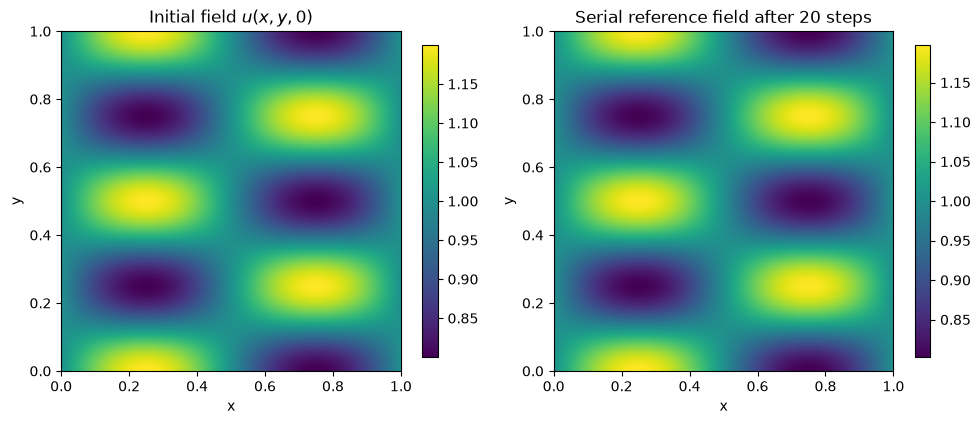

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
im0 = axes[0].imshow(u0.T, origin="lower", extent=[0, 1, 0, 1], cmap="viridis")
axes[0].set_title("Initial field $u(x,y,0)$")
axes[0].set_xlabel("x")
axes[0].set_ylabel("y")
fig.colorbar(im0, ax=axes[0], shrink=0.85)

im1 = axes[1].imshow(serial_history[STEPS].T, origin="lower", extent=[0, 1, 0, 1], cmap="viridis")
axes[1].set_title(f"Serial reference field after {STEPS} steps")
axes[1].set_xlabel("x")
axes[1].set_ylabel("y")
fig.colorbar(im1, ax=axes[1], shrink=0.85)
fig.tight_layout()
plt.show()

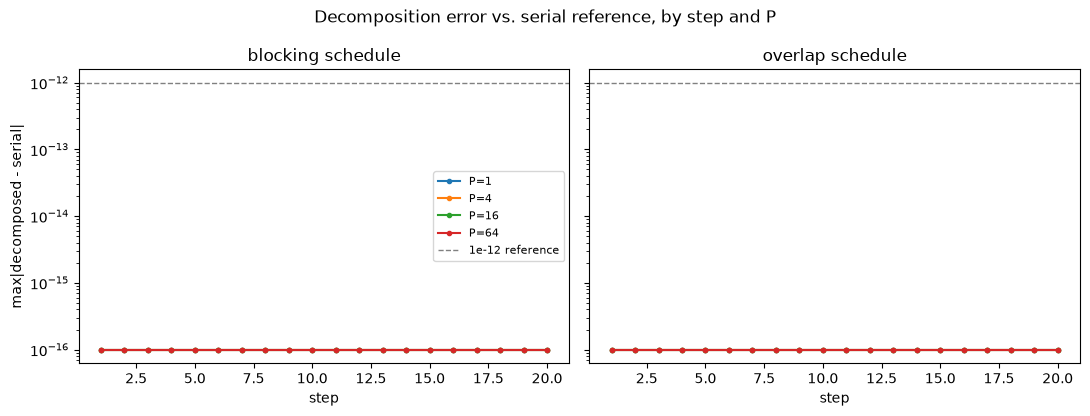

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
eps = 1e-16
for ax, schedule in zip(axes, SCHEDULES):
    for P, dims in DECOMPOSITIONS:
        blocks = split_global(u0, dims)
        errs = []
        for step in range(1, STEPS + 1):
            blocks, _ = decomposed_step(blocks, dims, schedule)
            gathered = gather_global(blocks, dims)
            errs.append(max(np.max(np.abs(gathered - serial_history[step])), eps))
        ax.semilogy(range(1, STEPS + 1), errs, marker="o", markersize=3, label=f"P={P}")
    ax.set_title(f"{schedule} schedule")
    ax.set_xlabel("step")
    ax.axhline(1e-12, color="gray", linestyle="--", linewidth=1, label="1e-12 reference")
axes[0].set_ylabel("max|decomposed - serial|")
axes[0].legend(fontsize=8)
fig.suptitle("Decomposition error vs. serial reference, by step and P")
fig.tight_layout()
plt.show()

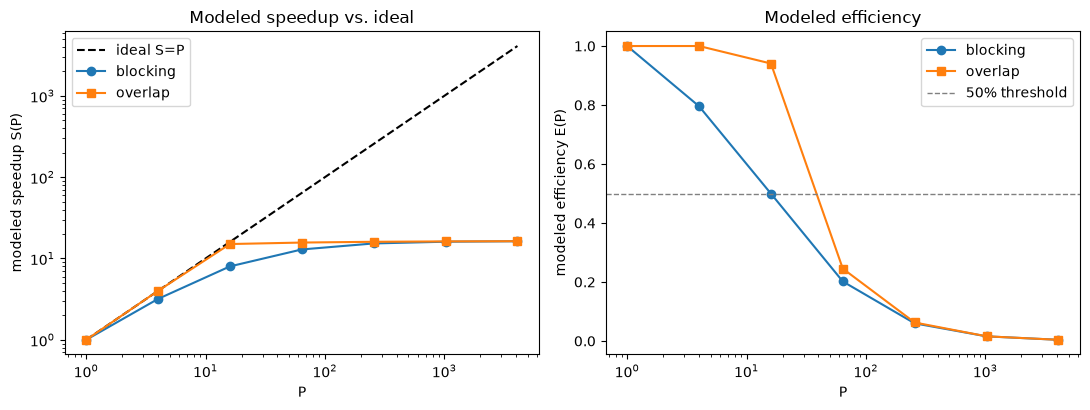

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
Ps = np.array(P_GRID, dtype=float)
S_block = np.array([r["S_block"] for r in default_rows])
S_overlap = np.array([r["S_overlap"] for r in default_rows])
E_block = np.array([r["E_block"] for r in default_rows])
E_overlap = np.array([r["E_overlap"] for r in default_rows])

axes[0].loglog(Ps, Ps, "k--", label="ideal S=P")
axes[0].loglog(Ps, S_block, "o-", label="blocking")
axes[0].loglog(Ps, S_overlap, "s-", label="overlap")
axes[0].set_xlabel("P")
axes[0].set_ylabel("modeled speedup S(P)")
axes[0].set_title("Modeled speedup vs. ideal")
axes[0].legend()

axes[1].semilogx(Ps, E_block, "o-", label="blocking")
axes[1].semilogx(Ps, E_overlap, "s-", label="overlap")
axes[1].axhline(0.5, color="gray", linestyle="--", linewidth=1, label="50% threshold")
axes[1].set_xlabel("P")
axes[1].set_ylabel("modeled efficiency E(P)")
axes[1].set_title("Modeled efficiency")
axes[1].legend()
fig.tight_layout()
plt.show()

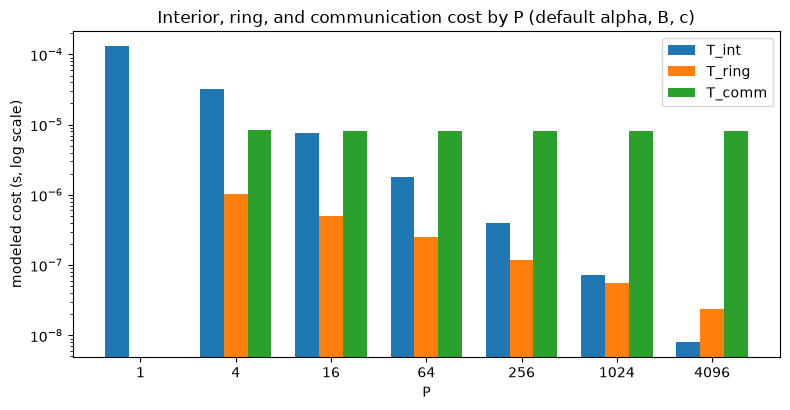

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.2))
width = 0.25
idx = np.arange(len(P_GRID))
T_int = np.array([r["T_int"] for r in default_rows])
T_ring = np.array([r["T_ring"] for r in default_rows])
T_comm = np.array([r["T_comm"] for r in default_rows])

ax.bar(idx - width, T_int, width, label="T_int")
ax.bar(idx, T_ring, width, label="T_ring")
ax.bar(idx + width, T_comm, width, label="T_comm")
ax.set_yscale("log")
ax.set_xticks(idx)
ax.set_xticklabels([str(P) for P in P_GRID])
ax.set_xlabel("P")
ax.set_ylabel("modeled cost (s, log scale)")
ax.set_title("Interior, ring, and communication cost by P (default alpha, B, c)")
ax.legend()
fig.tight_layout()
plt.show()

### Byte accounting

Face bytes per rank are $4nb$ (four faces, $n$ float64 values each); aggregate sent bytes across all ranks are $P$ times that per-rank amount (a sent face and its matching receive are the same transfer, counted once as "sent"); the surface/work ratio is $4/n$ (perimeter cells touched by messages divided by the $n$ interior cells per row of work). At $P=1$ no messages exist, so both are reported as zero.

In [11]:
byte_header = "| P | n | face bytes/rank | aggregate sent bytes | surface/work ratio 4/n |"
byte_sep = "|---|---|---|---|---|"
byte_rows = [byte_header, byte_sep]
for P, dims in DECOMPOSITIONS:
    n = N // dims[0]
    if P == 1:
        face_bytes, aggregate_bytes = 0, 0
    else:
        face_bytes = 4 * n * BYTES_PER_FLOAT
        aggregate_bytes = P * face_bytes
    byte_rows.append(f"| {P} | {n} | {face_bytes} | {aggregate_bytes} | {4/n:.4f} |")
display(Markdown("\n".join(byte_rows)))

| P | n | face bytes/rank | aggregate sent bytes | surface/work ratio 4/n |
|---|---|---|---|---|
| 1 | 256 | 0 | 0 | 0.0156 |
| 4 | 128 | 4096 | 16384 | 0.0312 |
| 16 | 64 | 2048 | 32768 | 0.0625 |
| 64 | 32 | 1024 | 65536 | 0.1250 |

### Interactive sensitivity explorer

Select $\alpha$ and $B$ from the dropdown to see the modeled overlap-efficiency curve $E_{overlap}(P)$ and where it crosses the 50% threshold.

In [12]:
fig = go.Figure()
buttons = []
for i, alpha in enumerate(ALPHAS):
    for j, bandwidth in enumerate(BANDWIDTHS):
        rows = sensitivity[(alpha, bandwidth)]
        e_over = [r["E_overlap"] for r in rows]
        visible = (i == 1 and j == 1)
        fig.add_trace(go.Scatter(
            x=P_GRID, y=e_over, mode="lines+markers",
            name=f"alpha={alpha*1e6:.1f}us, B={bandwidth/1e9:.0f}GB/s",
            visible=visible,
        ))

fig.add_hline(y=0.5, line_dash="dash", line_color="gray", annotation_text="50% threshold")

trace_index = 0
for alpha in ALPHAS:
    for bandwidth in BANDWIDTHS:
        vis = [False] * (len(ALPHAS) * len(BANDWIDTHS))
        vis[trace_index] = True
        buttons.append(dict(
            label=f"alpha={alpha*1e6:.1f}us, B={bandwidth/1e9:.0f}GB/s",
            method="update",
            args=[{"visible": vis}],
        ))
        trace_index += 1

fig.update_layout(
    title="Modeled overlap efficiency vs. P, by latency and bandwidth",
    xaxis=dict(title="P", type="log"),
    yaxis=dict(title="E_overlap(P)", range=[0, 1.05]),
    updatemenus=[dict(buttons=buttons, direction="down", x=1.0, xanchor="right", y=1.18, yanchor="top")],
    height=520,
)

plotly_html_path = Path("20261015-halo-sensitivity-interactive.html")
fig.write_html(plotly_html_path, include_plotlyjs="cdn", full_html=True, div_id="halo-sensitivity-explorer")
print(f"Generated {plotly_html_path}")

Generated 20261015-halo-sensitivity-interactive.html


<iframe
  src="20261015-halo-sensitivity-interactive.html"
  title="Modeled overlap efficiency vs. P, by latency and bandwidth"
  width="100%"
  height="560"
  style="border: 0;"
  loading="lazy"
></iframe>

## 6. Automatic checks

Assertions (no mesh sweep or observed-order analysis is required — this notebook checks algorithmic exactness, not discretization accuracy):
- `split_global`/`gather_global` are exact for a seeded random array, for every $P$.
- Every halo face matches its global periodic neighbor (checked in Section 2 via `halo_matches_global_id`).
- Both schedules match the serial reference within $10^{-12}$ maximum absolute difference after 20 steps, for every $P$.
- Every owned cell is written exactly once per step (write-coverage diagnostic).
- Periodic total mass changes by less than $10^{-12}$ relative scale.
- A constant field is preserved exactly by the stencil.
- All modeled times are positive; $T_{overlap}\le T_{block}$; the modeled overlap gain never exceeds $\min(T_{int},T_{comm})$; $P=1$ speedup and efficiency equal 1.
- $P=4$ regression: opposite processor-grid directions can share the same physical neighbor, but each direction must still receive the face assigned to it.

In [13]:
rng = np.random.default_rng(0)
rand_field = rng.standard_normal((N, N))
for P, dims in DECOMPOSITIONS:
    blocks = split_global(rand_field, dims)
    assert np.array_equal(gather_global(blocks, dims), rand_field), f"split/gather not exact for P={P}"
print("split/gather exact for all P: OK")

for P, dims in DECOMPOSITIONS:
    assert halo_matches_global_id(dims), f"halo mismatch for P={P}"
print("halo faces match global periodic neighbor for all P: OK")

for P, dims in DECOMPOSITIONS:
    for schedule in SCHEDULES:
        err = comparisons[(P, schedule, STEPS)]
        assert err < 1e-12, f"P={P} {schedule} diff {err} exceeds tolerance"
print("both schedules match serial reference within 1e-12 after 20 steps: OK")

for P, dims in DECOMPOSITIONS:
    for schedule in SCHEDULES:
        blocks = split_global(u0, dims)
        _, writes = decomposed_step(blocks, dims, schedule, track_writes=True)
        for key, wc in writes.items():
            assert np.array_equal(wc, np.ones_like(wc)), f"write coverage fail P={P} {schedule} block={key}"
print("every owned cell written exactly once per step, all P and schedules: OK")

initial_mass = u0.sum()
for P, dims in DECOMPOSITIONS:
    for schedule in SCHEDULES:
        blocks = split_global(u0, dims)
        for _ in range(STEPS):
            blocks, _ = decomposed_step(blocks, dims, schedule)
        mass = gather_global(blocks, dims).sum()
        rel_drift = abs(mass - initial_mass) / abs(initial_mass)
        assert rel_drift < 1e-12, f"mass drift {rel_drift} too large for P={P} {schedule}"
print("periodic total mass conserved to 1e-12 relative scale, all P and schedules: OK")

constant = np.full((N, N), 3.25)
assert np.allclose(serial_step(constant), constant, atol=1e-14, rtol=0.0)
print("constant field preserved exactly: OK")

for r in default_rows:
    assert r["T_block"] > 0 and r["T_overlap"] > 0, f"non-positive modeled time at P={r['P']}"
    assert r["T_overlap"] <= r["T_block"] + 1e-12, f"T_overlap > T_block at P={r['P']}"
    if r["P"] > 1:
        gain = r["T_block"] - r["T_overlap"]
        assert gain <= min(r["T_int"], r["T_comm"]) + 1e-9, f"overlap gain exceeds bound at P={r['P']}"
assert default_rows[0]["S_block"] == 1.0 and default_rows[0]["E_block"] == 1.0
assert default_rows[0]["S_overlap"] == 1.0 and default_rows[0]["E_overlap"] == 1.0
print("modeled-time bounds and P=1 speedup/efficiency == 1: OK")

P4_dims = (2, 2)
P4_blocks = split_global(np.arange(N * N, dtype=float).reshape(N, N), P4_dims)
exchange_halos(P4_blocks, P4_dims)
n4 = N // 2
ids = np.arange(N * N, dtype=float).reshape(N, N)
for (r, c), blk in P4_blocks.items():
    up_row = (r * n4 - 1) % N
    down_row = (r * n4 + n4) % N
    assert up_row != down_row  # with d=2 these ARE distinct rows even though the rank is the same
    cols = np.arange(c * n4, c * n4 + n4) % N
    assert np.array_equal(blk[0, 1:-1], ids[up_row, cols])
    assert np.array_equal(blk[-1, 1:-1], ids[down_row, cols])
print("P=4 shared-neighbor regression (opposite directions receive distinct, correct faces): OK")

print("\nAll automatic checks passed.")

split/gather exact for all P: OK
halo faces match global periodic neighbor for all P: OK
both schedules match serial reference within 1e-12 after 20 steps: OK
every owned cell written exactly once per step, all P and schedules: OK
periodic total mass conserved to 1e-12 relative scale, all P and schedules: OK
constant field preserved exactly: OK
modeled-time bounds and P=1 speedup/efficiency == 1: OK
P=4 shared-neighbor regression (opposite directions receive distinct, correct faces): OK

All automatic checks passed.


## 7. Discussion and next steps

**Why rank count eventually starves the overlap:** interior work per rank scales like $(n-2)^2\sim N^2/P$, so it shrinks quadratically as $P$ grows at fixed global size, while each rank's communication cost $T_{comm}=4\alpha+4nb/B$ falls only linearly in $n\sim 1/\sqrt P$ and is bounded below by the per-message latency floor $4\alpha$ that never vanishes. Past the crossover ($T_{int}<T_{comm}$, first at $P=16$ with the default parameters above), there is simply not enough independent interior work left to hide behind communication, and $T_{overlap}\to T_{ring}+T_{comm}$ is latency-dominated.

**Why nonblocking calls alone are not asynchronous progress:** posting `MPI_Isend`/`MPI_Irecv` only *permits* overlap; the MPI implementation must actually make independent forward progress on the transfer (e.g., via a dedicated thread, RDMA/DMA offload, or the application periodically re-entering the MPI library) while the application computes. Without genuine progress, "overlapped" code degenerates to blocking behavior anyway, or requires explicit progress calls between the post and the wait. $T_{overlap}$ above is a best-case bound assuming perfect progress, not a guarantee any API provides for free.

**Latency vs. bandwidth vs. synchronization:** $\alpha$ (latency) is a fixed per-message cost independent of payload size and dominates small messages; $4nb/B$ (bandwidth term) grows with face size $n$ and dominates for large blocks; neither includes *synchronization* cost — the time a rank idles waiting for a slower neighbor (load imbalance, jitter, contention), which this idealized model assumes is zero. Real measured efficiency is always at or below this idealized bound.

**Stretch (15-25 minutes):** Translate face exchange to `mpi4py` using `Irecv`/`Isend` and `Waitall` with NumPy buffers. Post receives first, keep send buffers immutable until completion, and compute only the strict interior before `Waitall`. Use distinct directional tags, including when two directions share a neighbor. Run with `mpiexec -n 4`; measure the maximum elapsed rank time after warm-up and use at least five repeats. Report MPI version, process binding, node count, and variability. Compare measured results with the model without claiming that the synthetic model predicts your hardware exactly.

**Paper:** Gerald Collom, Jason Burmark, Olga Pearce, and Amanda Bienz. Persistent and Partitioned MPI for Stencil Communication. arXiv:2508.13370, submitted August 18, 2025. DOI: 10.48550/arXiv.2508.13370. Open manuscript: https://arxiv.org/abs/2508.13370 . Learn how persistent requests amortize setup and partitioned operations expose readiness; inspect dependence on process count, threads, and message size. Reported best-case gains are not universal speedups.

**Dedicated implementation reference:** MPI for Python official tutorial, https://mpi4py.readthedocs.io/en/stable/tutorial.html . Focus on direct NumPy buffer communication, request completion, and buffer lifetime. This MPI topic is better served by authoritative MPI documentation than a NASA Glenn aerodynamics page.

**History audit - last seven preceding projects:**

| Date | Primary objective |
|---|---|
| 2026-09-29 | Verify heat conduction |
| 2026-09-30 | Solver error |
| 2026-10-01 | Estimating mesh error |
| 2026-10-02 | Heat balance uncertainty |
| 2026-10-05 | Grid convergence and discretization uncertainty |
| 2026-10-06 | Fixed-mesh transport stability, conservation, positivity and TV |
| 2026-10-07 | Krylov preconditioning and spectra |
| 2026-10-08 | Memory layout and flux-kernel throughput |
| 2026-10-09 | Nonlinear natural-circulation thermal-fluid model |
| 2026-10-12 | Discrete-adjoint PDE optimization |
| 2026-10-13 | Partitioned multiphysics coupling and relaxation |
| 2026-10-14 | Characteristic WENO-Z shock reconstruction |
| 2026-10-15 | Parallel domain decomposition, halo scheduling and scaling |

The seven preceding notebooks were inspected before selection. Today is assignment 7 of the ten-assignment grid-study exclusion; three remain after today. Next rotation: time integration, uncertainty propagation, turbulence modeling. Template reference: https://github.com/josh-fowler-hub/daily-learning/blob/main/problem-template.ipynb .